
## EX9 Unsupervised Learning

### Clustering

Basic use of common clustering models

- K-means

- DBSCAN

### Part 0

- Examples of the use of K-means and its comparisons with DBSCAN.

In [27]:
# Python ≥3.5 is required
import sys
assert sys.version_info >= (3, 5)

# Scikit-Learn ≥0.20 is required
import sklearn
assert sklearn.__version__ >= "0.20"

# Common imports
import numpy as np
import pandas as pd
import seaborn as sn
import os

# to make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)


# Where to save the figures
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "clustering_kmeans"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Ignore useless warnings (see SciPy issue #5998)
import warnings
warnings.filterwarnings(action="ignore", message="^internal gelsd")

### Utility functions

In [28]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_labelled_scatter(X, y, class_labels):
    num_labels = len(class_labels)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    marker_array = ['o', '^', '*']
    color_array = ['#FFFF00', '#00AAFF', '#000000', '#FF00AA']
    cmap_bold = ListedColormap(color_array)
    bnorm = BoundaryNorm(np.arange(0, num_labels + 1, 1), ncolors=num_labels)
    plt.figure()

    plt.scatter(X[:, 0], X[:, 1], s=65, c=y, cmap=cmap_bold, norm = bnorm, alpha = 0.40, edgecolor='black', lw = 1)

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    h = []
    for c in range(0, num_labels):
        h.append(mpatches.Patch(color=color_array[c], label=class_labels[c]))
    plt.legend(handles=h)
    plt.show()


def plot_dbscan(dbscan, X, size, show_xlabels=True, show_ylabels=True):
    core_mask = np.zeros_like(dbscan.labels_, dtype=bool)
    core_mask[dbscan.core_sample_indices_] = True
    anomalies_mask = dbscan.labels_ == -1
    non_core_mask = ~(core_mask | anomalies_mask)

    cores = dbscan.components_
    anomalies = X[anomalies_mask]
    non_cores = X[non_core_mask]

    plt.scatter(cores[:, 0], cores[:, 1],
                c=dbscan.labels_[core_mask], marker='o', s=size, cmap="Paired")
    plt.scatter(cores[:, 0], cores[:, 1], marker='*', s=20, c=dbscan.labels_[core_mask])
    plt.scatter(anomalies[:, 0], anomalies[:, 1],
                c="r", marker="x", s=100)
    plt.scatter(non_cores[:, 0], non_cores[:, 1], c=dbscan.labels_[non_core_mask], marker=".")
    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title("eps={:.2f}, min_samples={}".format(dbscan.eps, dbscan.min_samples), fontsize=14)

### K-means model

The K-Means algorithm is one of the fastest clustering algorithms, but also one of the simplest:
* First initialize $k$ centroids randomly: $k$ distinct instances are chosen randomly from the dataset and the centroids are placed at their locations.
* Repeat until convergence (i.e., until the centroids stop moving):
    * Assign each instance to the closest centroid.
    * Update the centroids to be the mean of the instances that are assigned to them.
    
    
The `KMeans` class applies an optimized algorithm by default. To get the original K-Means algorithm (for educational purposes only), you must set `init="random"`, `n_init=1`and `algorithm="full"`. These hyperparameters will be explained below.

### 1. A synthetic dataset

This example creates a synthetic dataset with make_blobs, then applies k-means to find 3 clusters, and plots the points in each cluster identified by a corresponding color.

#### Generate a dataset

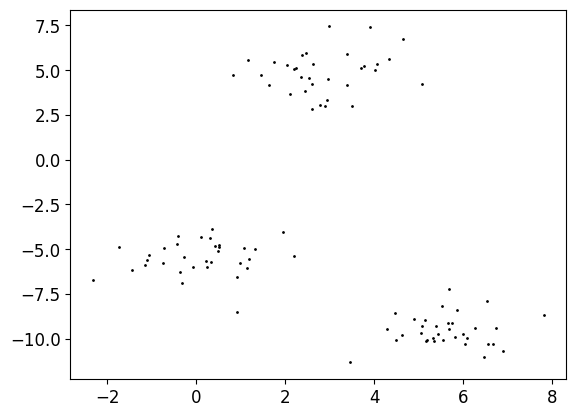

In [29]:
from sklearn.datasets import make_blobs

rand_state = 10

X, y = make_blobs(random_state = rand_state)

plot_data(X)

#### K-means model

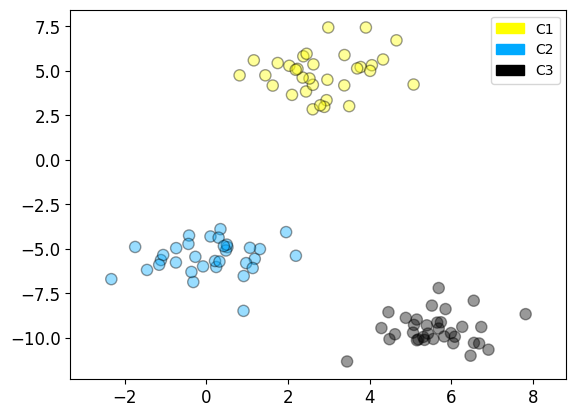

In [30]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3)
kmeans.fit(X)

plot_labelled_scatter(X, kmeans.labels_, ['C1', 'C2', 'C3'])

### 2. Real dataset: Fruit dataset

#### Load the data

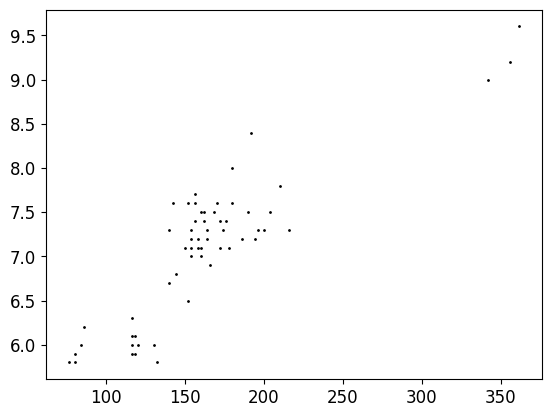

In [31]:
fruits = pd.read_csv('/content/fruit_data_with_colors.txt', sep='\t', engine='python')

X_fruits = fruits[['mass','width','height', 'color_score']].values
y_fruits = fruits[['fruit_label']] - 1


# plot the data (only use 2 attributes, 'mass', 'width')
plot_data(X_fruits)

#### Standarizing the data (scaling)

- Note that in general, it's important to scale the individual features before applying k-means clustering.

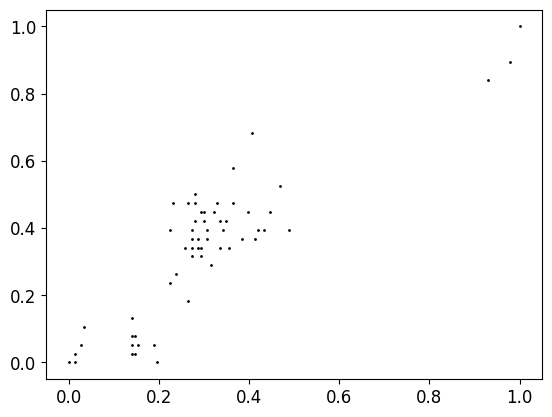

In [32]:
from sklearn.preprocessing import MinMaxScaler


from sklearn.preprocessing import MinMaxScaler

X_normalized = MinMaxScaler().fit(X_fruits).transform(X_fruits)

plot_data(X_normalized)

#### K-means model

- This example showing k-means used to find 4 clusters in the fruits dataset.

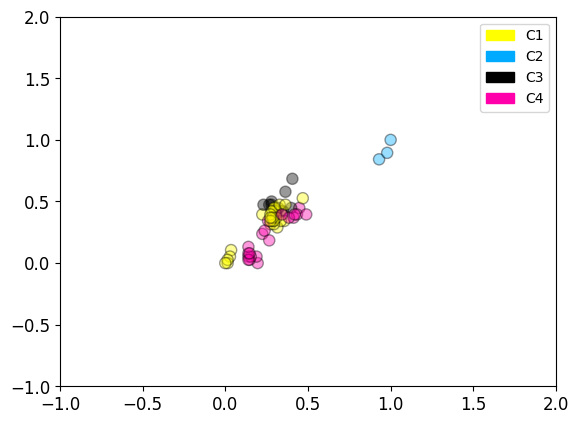

In [33]:
from sklearn.cluster import KMeans


kmeans = KMeans(n_clusters=4, random_state=0)
kmeans.fit(X_normalized)

plot_labelled_scatter(X_normalized, kmeans.labels_, ['C1', 'C2', 'C3', 'C4'])

### 3. k-means vs. DBSCAN clustering

### (1) A simple dataset

#### Generate a dataset

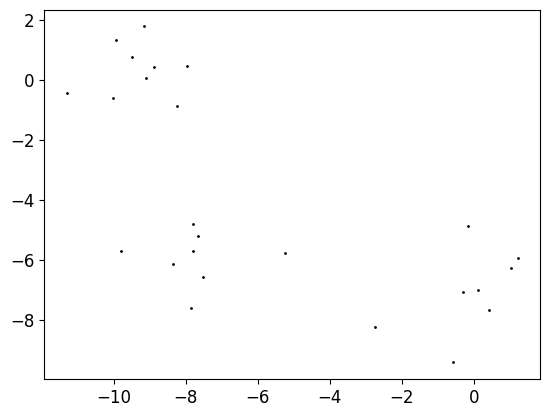

In [34]:
from sklearn.datasets import make_blobs

X, y = make_blobs(random_state = 9, n_samples = 25)

plot_data(X)

#### K-means model

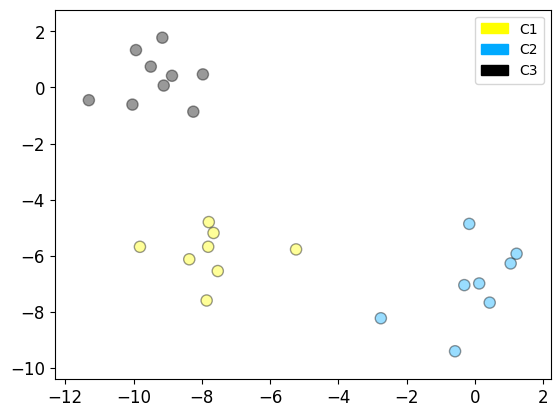

In [35]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3)
kmeans.fit(X)

plot_labelled_scatter(X, kmeans.labels_, ['C1', 'C2', 'C3'])

#### DBSCAN model

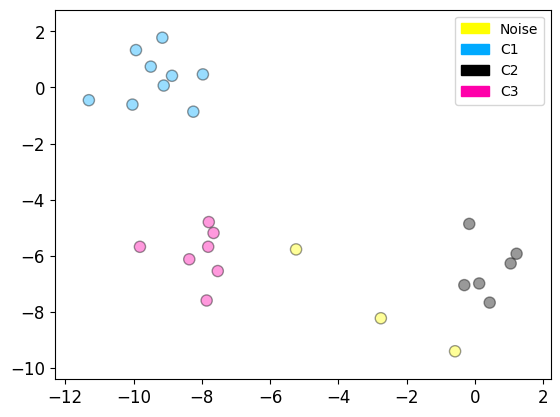

In [36]:
from sklearn.cluster import DBSCAN


dbscan = DBSCAN(eps = 2, min_samples= 2)
cls = dbscan.fit_predict(X)

plot_labelled_scatter(X, cls + 1, ['Noise', 'C1', 'C2', 'C3'])

### (2) K-Means and DBSCAN on a more complex dataset


#### Generate a synthetic dataset

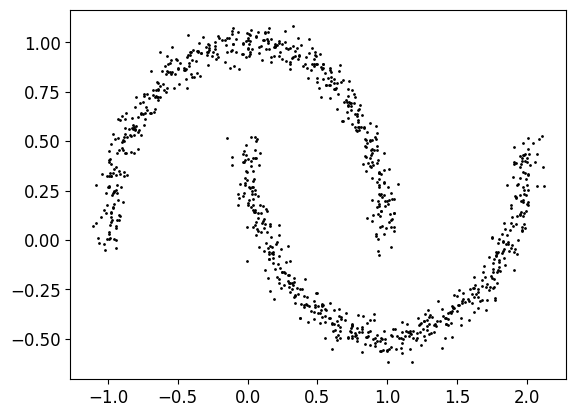

In [37]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)

plot_data(X)

#### K-means model


- Apply k-means model

- use k = 2

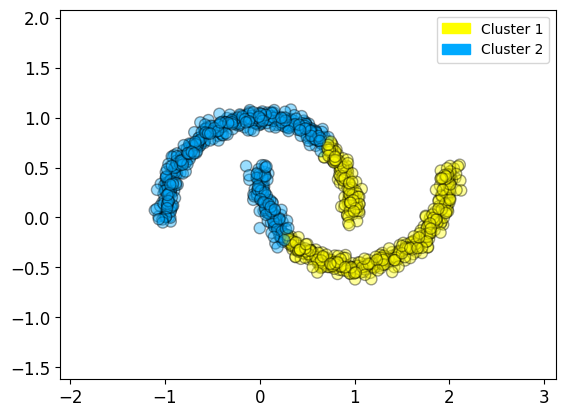

In [38]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters = 2)
kmeans.fit(X)

plot_labelled_scatter(X, kmeans.labels_, ['Cluster 1', 'Cluster 2'])

#### DBSCAN model

- Apply DBSCAN model

- use eps=0.2, min_samples=5

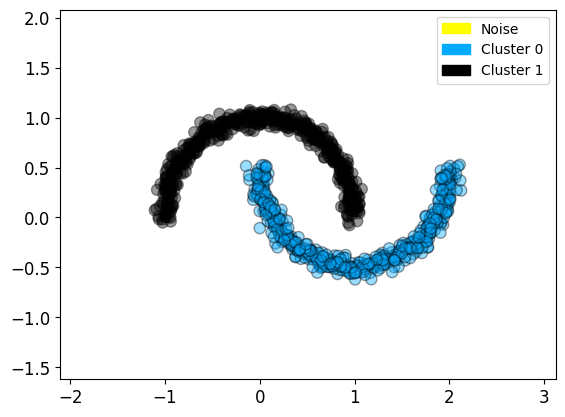

In [39]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.2, min_samples=5)
cls = dbscan.fit_predict(X)

plot_labelled_scatter(X, cls + 1, ['Noise', 'Cluster 0', 'Cluster 1'])

### (3) Apply k-means model on breast cancer dataset and check the model performance

#### A simple evaluation on K-means

- Apply k-means model with k = 2

- print the sum of all correctly predicted data (y_predicted==y_cancer)

- Since we have y_cancer values, we compare the predicted value to its y_cancer value. The ratio of correctly predicted class can represent the accuracy of the model.

#### load the data

- load breast cancer dataset from sklearn.datasets (set the parameter, return_X_y = True)

- normalize the data

In [40]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler

# Breast cancer dataset
cancer = load_breast_cancer()

(X_cancer, y_cancer) = load_breast_cancer(return_X_y = True)

# Normalization of data
X_normalized = MinMaxScaler().fit(X_cancer).transform(X_cancer)

#### K-Means on non-normalized data

In [41]:
from sklearn.cluster import KMeans

kmeans_no = KMeans(n_clusters = 2)
kmeans_no.fit(X_cancer)

y_predicted = kmeans_no.predict(X_cancer)

print(np.sum(y_predicted==y_cancer))

print(np.sum(y_predicted==y_cancer) / len(y_predicted))

83
0.14586994727592267


#### K-Means on normalized data

In [42]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters = 2)
kmeans.fit(X_normalized)

y_predicted = kmeans.predict(X_normalized)

print(np.sum(y_predicted==y_cancer))

print(np.sum(y_predicted==y_cancer) / len(y_predicted))

41
0.07205623901581722


### (4) Evaluation Quality of Clusters - K-means

- We will apply two evaluation methods, Inertia and Silhouette score.

- Please read the documentation of these two methods:

    - https://scikit-learn.org/stable/modules/clustering.html

    - https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html
    
- Find Optimal k values based on the evaluation.


#### Inertia Measure

Sum of distances of samples to their closest cluster center

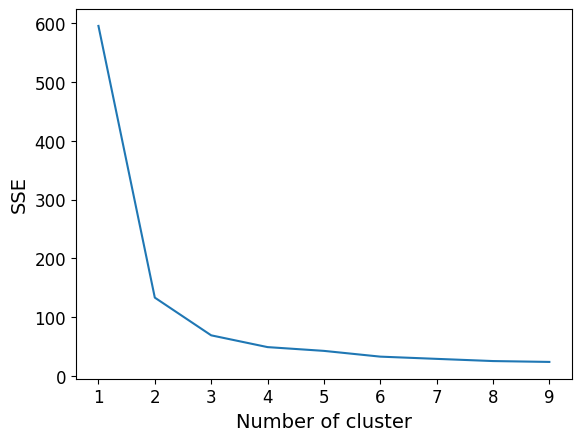

In [43]:
from sklearn.datasets import load_iris

iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris['feature_names'])
data = X[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']]

sse = {}
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, max_iter=1000).fit(data)
    # Inertia: Sum of distances of samples to their closest cluster center
    sse[k] = kmeans.inertia_

plt.figure()
plt.plot(list(sse.keys()), list(sse.values()))
plt.xlabel("Number of cluster")
plt.ylabel("SSE")
plt.show()

#### Silhouette Score

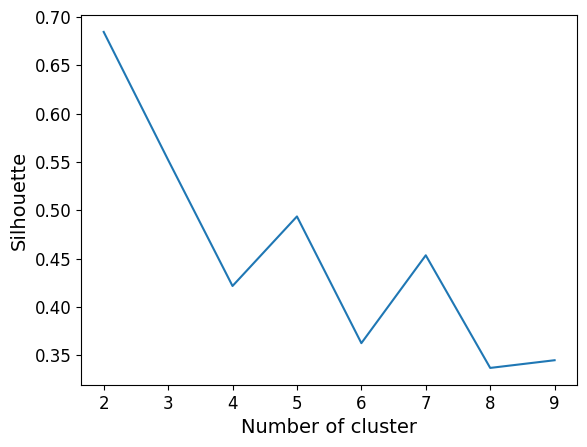

In [44]:
from sklearn.datasets import load_iris
from sklearn import metrics

iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris['feature_names'])
data = X[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']]

score = {}
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, max_iter=1000).fit(data)
    labels = kmeans.labels_

    score[k] = metrics.silhouette_score(data, labels, metric='euclidean')

plt.figure()
plt.plot(list(score.keys()), list(score.values()))
plt.xlabel("Number of cluster")
plt.ylabel("Silhouette")
plt.show()

### (5) Silhouette Score Example

For n_clusters = 2 The average silhouette_score is : 0.7049787496083262
For n_clusters = 3 The average silhouette_score is : 0.5882004012129721
For n_clusters = 4 The average silhouette_score is : 0.6505186632729437
For n_clusters = 5 The average silhouette_score is : 0.561464362648773
For n_clusters = 6 The average silhouette_score is : 0.4857596147013469


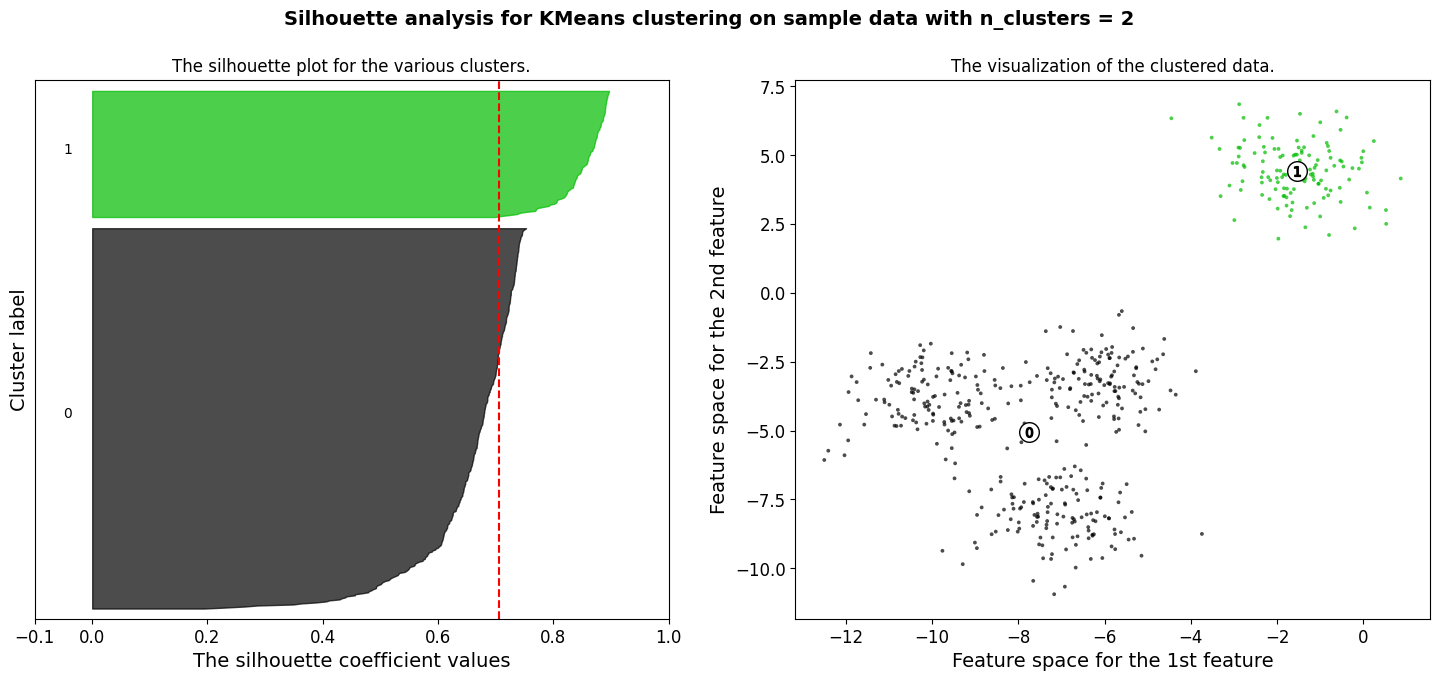

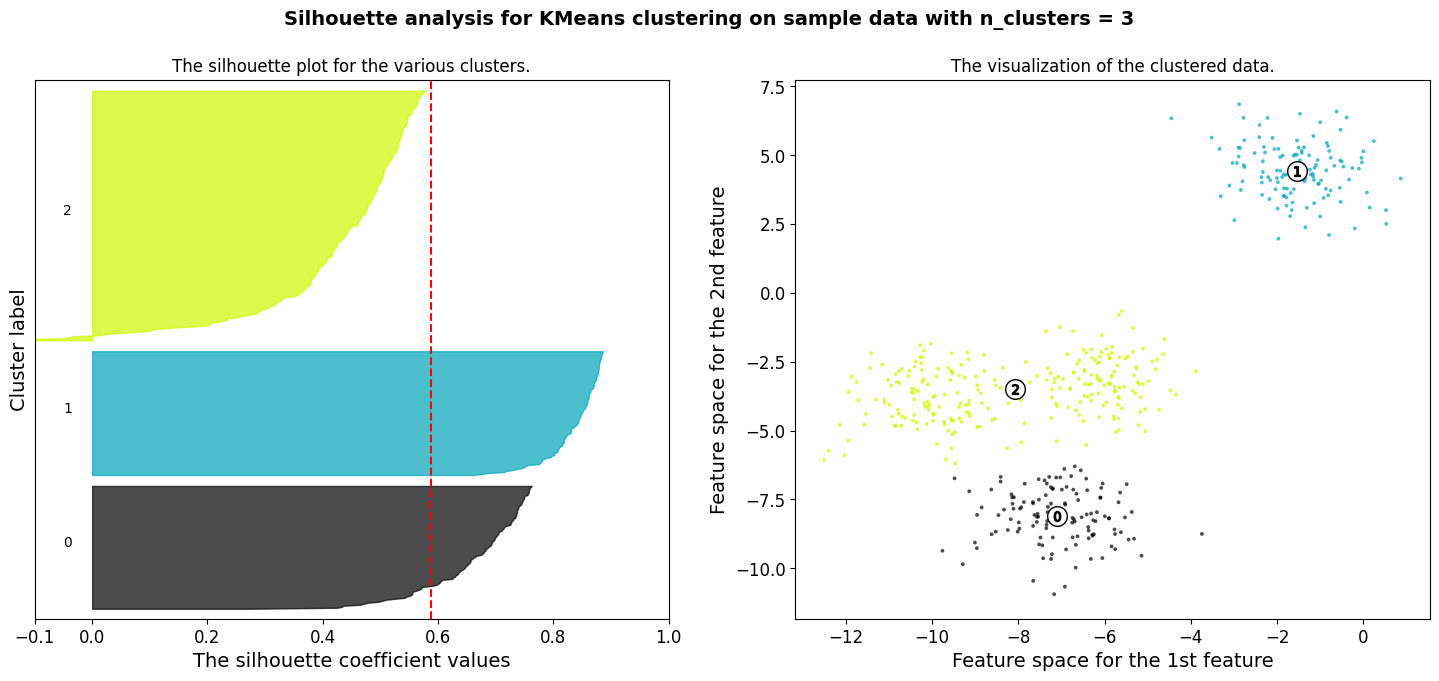

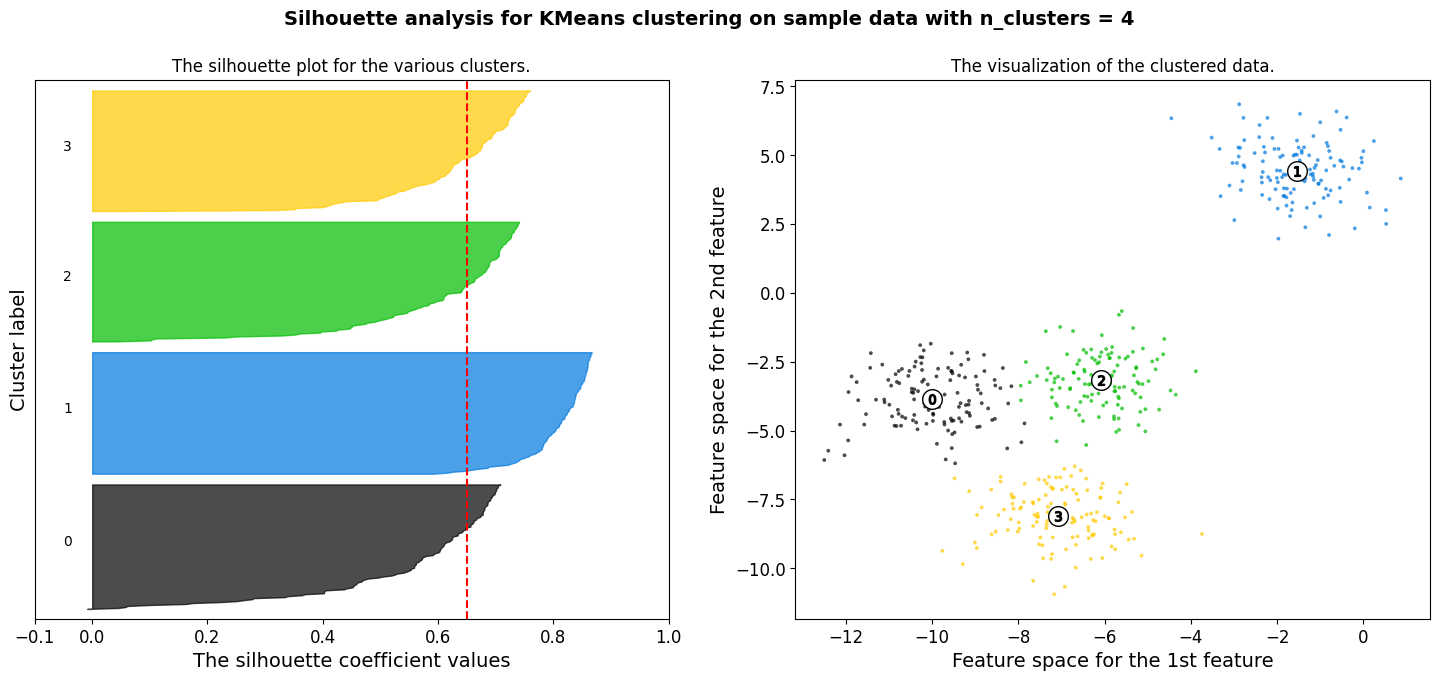

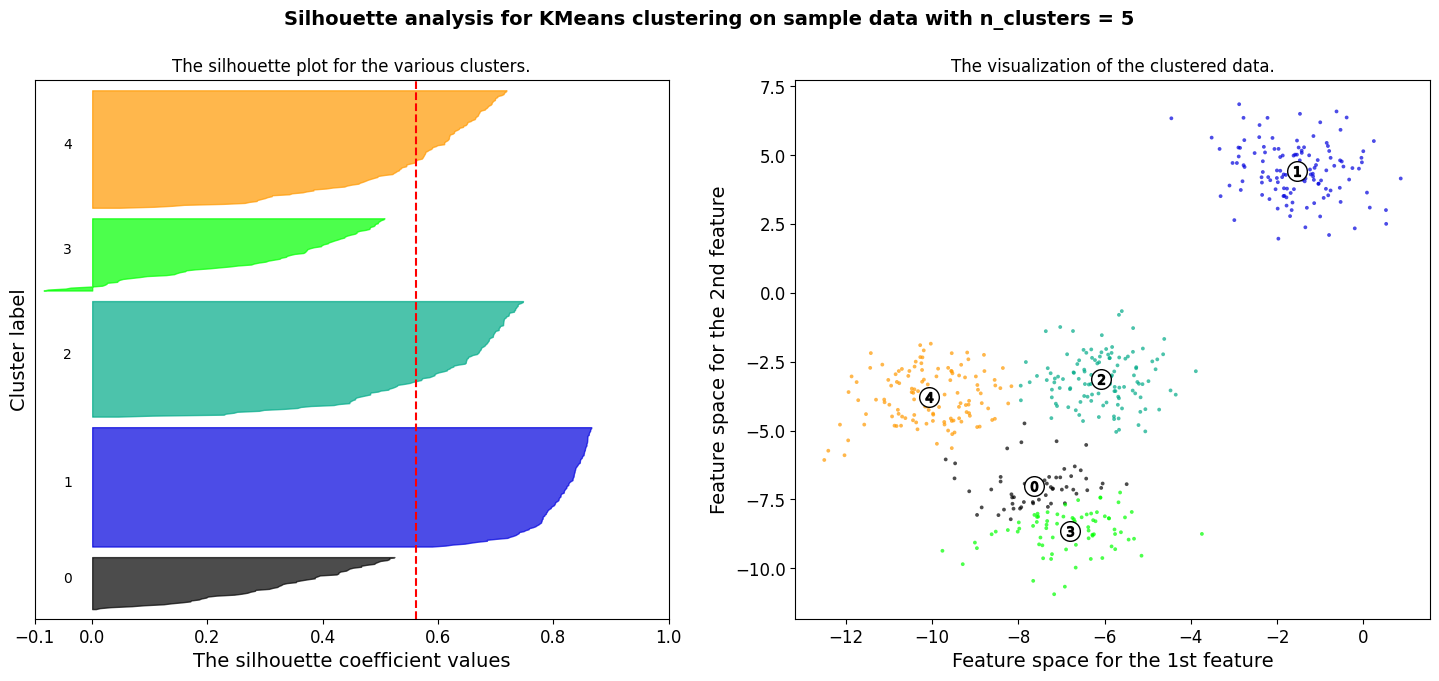

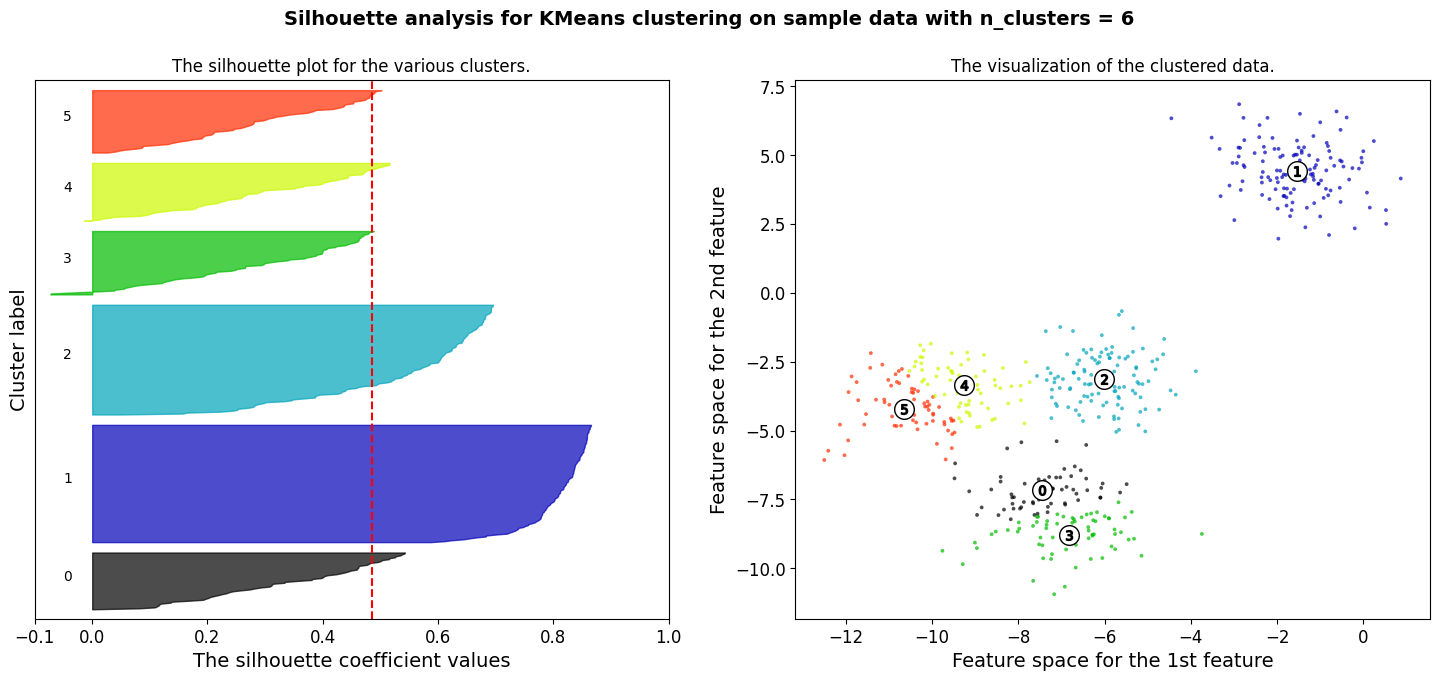

In [45]:
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm

# Generating the sample data from make_blobs
# This particular setting has one distinct cluster and 3 clusters placed close
# together.
X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=4,
    cluster_std=1,
    center_box=(-10.0, 10.0),
    shuffle=True,
    random_state=1,
)  # For reproducibility

range_n_clusters = [2, 3, 4, 5, 6]

for n_clusters in range_n_clusters:
    # Create a subplot with 1 row and 2 columns
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # The 1st subplot is the silhouette plot
    # The silhouette coefficient can range from -1, 1 but in this example all
    # lie within [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # The (n_clusters+1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    # Initialize the clusterer with n_clusters value and a random generator
    # seed of 10 for reproducibility.
    clusterer = KMeans(n_clusters=n_clusters, random_state=10)
    cluster_labels = clusterer.fit_predict(X)

    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed
    # clusters
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(
        "For n_clusters =",
        n_clusters,
        "The average silhouette_score is :",
        silhouette_avg,
    )

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Label the silhouette plots with their cluster numbers at the middle
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    ax1.set_title("The silhouette plot for the various clusters.")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")

    # The vertical line for average silhouette score of all the values
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Clear the yaxis labels / ticks
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # 2nd Plot showing the actual clusters formed
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )

    # Labeling the clusters
    centers = clusterer.cluster_centers_
    # Draw white circles at cluster centers
    ax2.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="o",
        c="white",
        alpha=1,
        s=200,
        edgecolor="k",
    )

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

    ax2.set_title("The visualization of the clustered data.")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(
        "Silhouette analysis for KMeans clustering on sample data with n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

## Part 1

### Task: Apply K-Means on your dataset

- Find out optimal k value(s) for the dataset through clustering evaluation.

    - Use two methods (Inertia and Silhouette score)

- Visualize the clusters

### Submissions:

- Upload the notebook (clustering_basic.ipynb) on GitHub.

- Write the names of students who worked on this assignment.

- Write the link to the notebook on Canvas.

## Part 1: K-Means on our dataset

**Students who worked on this assignment:** _(write names here)_

**Dataset:** `data/data_multivar.txt` – 200 unlabeled 2-D points. It has no class labels, so internal evaluation (Inertia and Silhouette) is the right way to choose *k*.

**Plan:** load → look at the data → Inertia (elbow) → Silhouette → pick k → visualize clusters.

(200, 2)


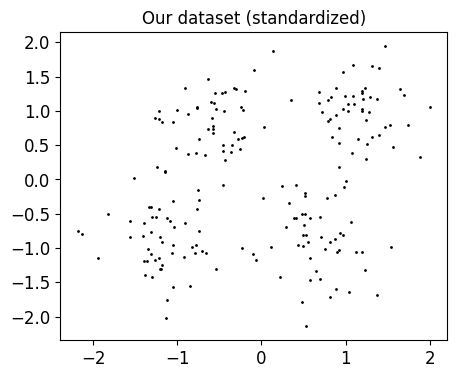

In [46]:
X_raw = np.loadtxt('/content/data_multivar.txt', delimiter=',')
print(X_raw.shape)

# Scale first: k-means is distance based
from sklearn.preprocessing import StandardScaler
X_my = StandardScaler().fit_transform(X_raw)

plt.figure(figsize=(5,4))
plot_data(X_my)
plt.title('Our dataset (standardized)')
plt.show()

### Method 1: Inertia (elbow method)

Inertia = sum of squared distances of points to their closest centroid. It always decreases as *k* grows, so we look for the "elbow" where improvement slows down.

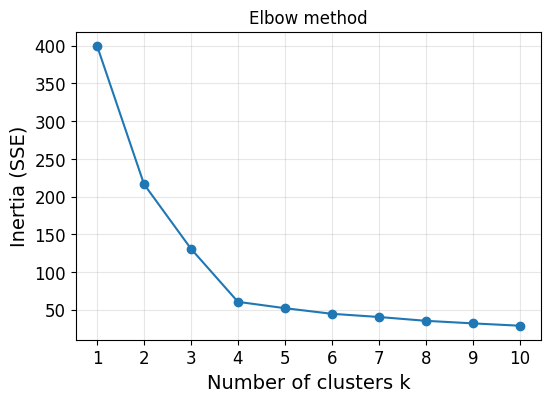

k=2: inertia= 216.55  drop vs k-1 =  45.9%
k=3: inertia= 131.00  drop vs k-1 =  39.5%
k=4: inertia=  60.65  drop vs k-1 =  53.7%
k=5: inertia=  52.25  drop vs k-1 =  13.8%
k=6: inertia=  44.81  drop vs k-1 =  14.2%
k=7: inertia=  40.59  drop vs k-1 =   9.4%
k=8: inertia=  35.51  drop vs k-1 =  12.5%
k=9: inertia=  32.13  drop vs k-1 =   9.5%
k=10: inertia=  29.01  drop vs k-1 =   9.7%


In [47]:
ks = range(1, 11)
inertia = {}
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_my)
    inertia[k] = km.inertia_

plt.figure(figsize=(6,4))
plt.plot(list(inertia.keys()), list(inertia.values()), 'o-')
plt.xlabel('Number of clusters k'); plt.ylabel('Inertia (SSE)')
plt.title('Elbow method'); plt.xticks(list(ks)); plt.grid(alpha=.3)
plt.show()

# Quantify the elbow: relative drop in inertia from k-1 to k
for k in range(2, 11):
    print(f'k={k}: inertia={inertia[k]:7.2f}  drop vs k-1 = {100*(1-inertia[k]/inertia[k-1]):5.1f}%')

### Method 2: Silhouette score

For each point: (b − a) / max(a, b), where a is the mean distance to its own cluster and b the mean distance to the nearest other cluster. Range −1 to 1; **higher is better**. We pick the *k* with the highest average score.

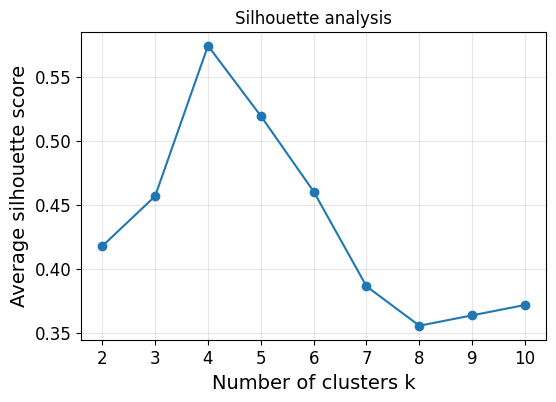

k=2: silhouette=0.4175
k=3: silhouette=0.4566
k=4: silhouette=0.5741
k=5: silhouette=0.5192
k=6: silhouette=0.4602
k=7: silhouette=0.3861
k=8: silhouette=0.3553
k=9: silhouette=0.3634
k=10: silhouette=0.3716

Best k by silhouette: 4


In [48]:
from sklearn.metrics import silhouette_score

sil = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_my)
    sil[k] = silhouette_score(X_my, labels)

plt.figure(figsize=(6,4))
plt.plot(list(sil.keys()), list(sil.values()), 'o-')
plt.xlabel('Number of clusters k'); plt.ylabel('Average silhouette score')
plt.title('Silhouette analysis'); plt.xticks(range(2, 11)); plt.grid(alpha=.3)
plt.show()

best_k = max(sil, key=sil.get)
for k, s in sil.items(): print(f'k={k}: silhouette={s:.4f}')
print('\nBest k by silhouette:', best_k)

### Visualize the clusters

We show the best *k* from the silhouette score plus the neighboring values, so the choice can be compared visually. Black stars are centroids.

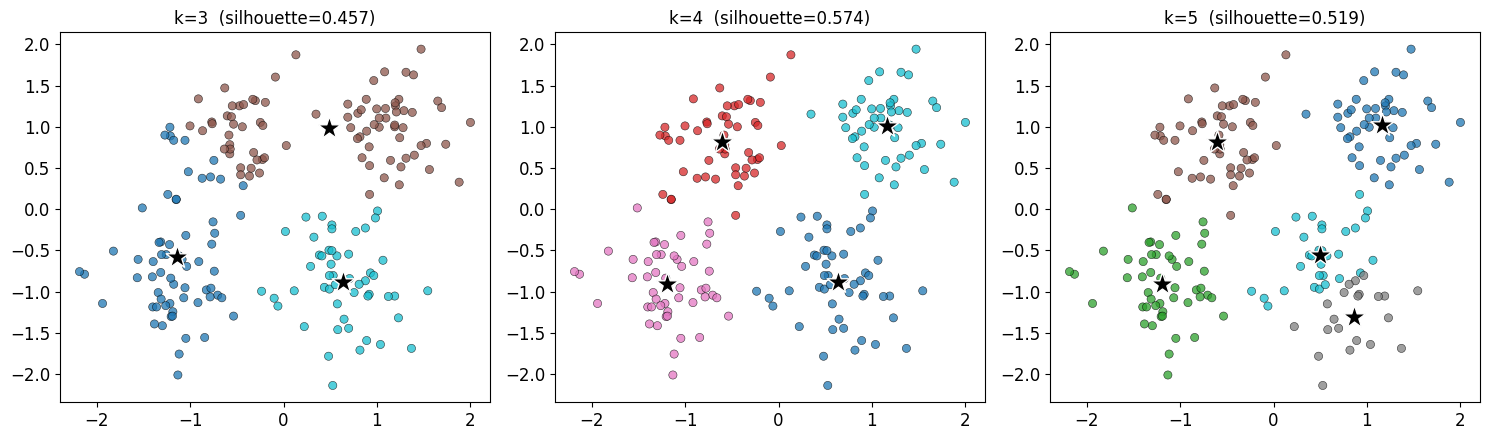

In [49]:
candidates = sorted({best_k - 1, best_k, best_k + 1} - {1})
fig, axes = plt.subplots(1, len(candidates), figsize=(5*len(candidates), 4.5))
for ax, k in zip(np.atleast_1d(axes), candidates):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_my)
    ax.scatter(X_my[:,0], X_my[:,1], c=km.labels_, cmap='tab10', s=35, alpha=.75, edgecolor='k', lw=.4)
    ax.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], marker='*', s=300, c='black', edgecolor='white')
    ax.set_title(f'k={k}  (silhouette={sil[k]:.3f})')
plt.tight_layout(); plt.show()

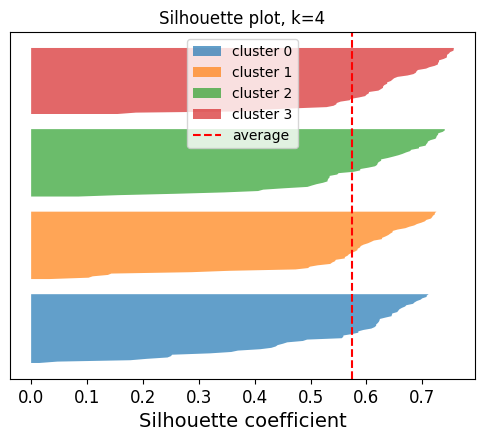

In [50]:
# Silhouette plot for the chosen k: shows per-cluster quality
from sklearn.metrics import silhouette_samples
km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X_my)
s = silhouette_samples(X_my, km.labels_)

plt.figure(figsize=(6,4.5))
y_low = 10
for i in range(best_k):
    si = np.sort(s[km.labels_ == i])
    plt.fill_betweenx(np.arange(y_low, y_low+len(si)), 0, si, alpha=.7, label=f'cluster {i}')
    y_low += len(si) + 10
plt.axvline(sil[best_k], color='red', ls='--', label='average')
plt.xlabel('Silhouette coefficient'); plt.yticks([]); plt.legend()
plt.title(f'Silhouette plot, k={best_k}'); plt.show()

### Conclusion

- **Inertia:** the curve drops sharply until k = 4 (the k=3→4 step cuts inertia by about 54%), then flattens (drops of only 9–14% per extra cluster). The elbow is at **k = 4**.
- **Silhouette:** the highest average score is at **k = 4** (0.574); k = 5 is second (0.519) and the score keeps falling after that.
- **Chosen k = 4.** Both methods agree, and the cluster plots show four compact, well-separated groups. Using k = 5 would split one natural group in two.